In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [2]:
df = pd.read_csv('/content/IPLPlayerStat.csv')

In [3]:
df[['batting_strike_rate']].head()

,batting_strike_rate
0,142.86
1,115.83
2,57.14
3,70.67
4,125.00


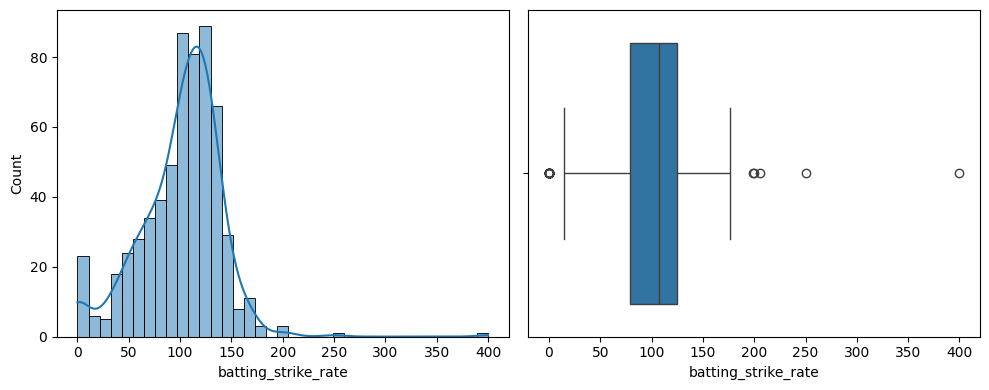

In [4]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.histplot(df['batting_strike_rate'],kde=True)

plt.subplot(1,2,2)
sns.boxplot(x=df['batting_strike_rate'])

plt.tight_layout()
plt.show()

Calculate IQR

In [11]:
Q1 = df['batting_strike_rate'].quantile(0.25)
Q3 = df['batting_strike_rate'].quantile(0.75)
median = df['batting_strike_rate'].quantile(0.50)

IQR = Q3-Q1

lower=Q1-1.5*IQR
upper = Q3+1.5*IQR

print("Q1:",Q1)
print("Median:",median)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower Fence:",lower)
print("Upper Fence:",upper)

Q1: 78.75
Median: 107.27
Q3: 125.0
IQR: 46.25
Lower Fence: 9.375
Upper Fence: 194.375


In [12]:
outlier = df[(df['batting_strike_rate']<lower) | (df['batting_strike_rate']>upper)]
print("Number of Outlier:",len(outlier))
outlier.head(

)

Number of Outlier: 28


,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings
57,57,AS Roy,0,0,2,2.0,57.0,66.0,3,0.00,0.0,0.0,6.95,33.00,28.50,5.0,0.0
63,63,Abdur Razzak,0,0,2,0.0,14.0,29.0,1,0.00,0.0,0.0,12.43,290000.00,140000.00,0.0,0.0
65,65,Akash Deep,0,0,2,5.0,119.0,206.0,5,0.00,0.0,0.0,10.39,41.20,23.80,1.0,0.0
83,83,B Stanlake,5,1,2,7.0,150.0,200.0,6,0.83,250.0,50.0,8.00,28.57,21.43,1.0,0.0
102,102,C Nanda,0,0,1,2.0,50.0,58.0,3,0.00,0.0,0.0,6.96,29.00,25.00,0.0,0.0


In [10]:
df.shape[0]

605

In [14]:
trim_df = df[(df['batting_strike_rate']>=lower)&(df['batting_strike_rate']<=upper)]
print('Original Shape:',df.shape)
print('Trim Shape:',trim_df.shape)

Original Shape: (605, 17)
Trim Shape: (577, 17)


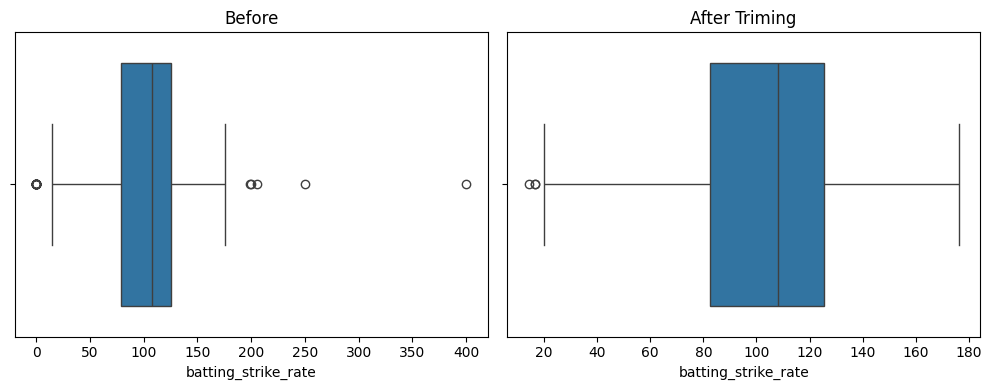

In [18]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)

sns.boxplot(x=df['batting_strike_rate'])
plt.title('Before')

plt.subplot(1,2,2)
sns.boxplot(x=trim_df['batting_strike_rate'])
plt.title("After Triming")

plt.tight_layout()
plt.show()

Capping

In [19]:
cap_df = df.copy()

cap_df['batting_strike_rate']=cap_df['batting_strike_rate'].clip(lower,upper)


In [20]:
print("Original Shape:",df.shape)
print("After Triming:",cap_df.shape)

Original Shape: (605, 17)
After Triming: (605, 17)


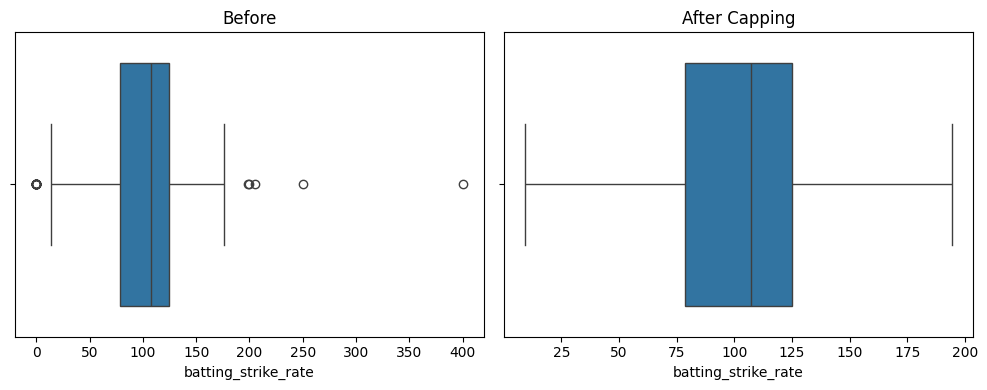

In [22]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)

sns.boxplot(x=df['batting_strike_rate'])
plt.title('Before')

plt.subplot(1,2,2)
sns.boxplot(x=cap_df['batting_strike_rate'])
plt.title("After Capping")

plt.tight_layout()
plt.show()